In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# import dataset
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df=pd.read_csv(url)

In [3]:
# First 10 rows of the dataset
df.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


In [4]:
# Number of rows and columns in the dataset
df.shape

(891, 15)

In [5]:
# whihc columns contain missing values and how many missing values are there in each column?
df.isnull().sum().reset_index()

,index,0
0,survived,0
1,pclass,0
2,sex,0
3,age,177
4,sibsp,0
5,parch,0
6,fare,0
7,embarked,2
8,class,0
9,who,0


In [6]:
# What was the average age of the passengers?
df['age'].mean()

29.69911764705882

In [7]:
# What was the average age of male passengers compared with female passengers?
df.groupby('sex')['age'].mean()

sex
female    27.915709
male      30.726645
Name: age, dtype: float64

In [8]:
# What percentage of passengers survived?
df['survived'].mean() * 100

38.38383838383838

In [9]:
# Which passenger class (pclass) had the highest survival rate?
df.groupby('pclass')['survived'].mean()

pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64

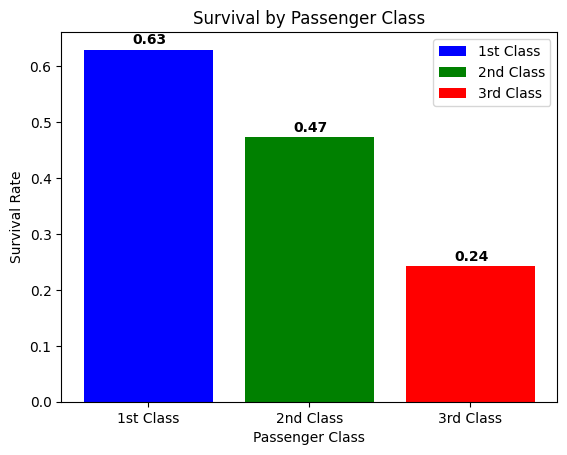

In [20]:
# Survival by passenger class plot
pclass_survival = df.groupby('pclass')['survived'].mean().reset_index()

plt.bar(pclass_survival['pclass'], pclass_survival['survived'], color=['blue', 'green', 'red'], label=['1st Class', '2nd Class', '3rd Class'])

for i, v in enumerate(pclass_survival['survived']):
    plt.text(pclass_survival['pclass'][i] - 0.1, v + 0.01, f"{v:.2f}", color='black', fontweight='bold')

plt.xticks(pclass_survival['pclass'], ['1st Class', '2nd Class', '3rd Class'])
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.title('Survival by Passenger Class')
plt.legend()
plt.show()

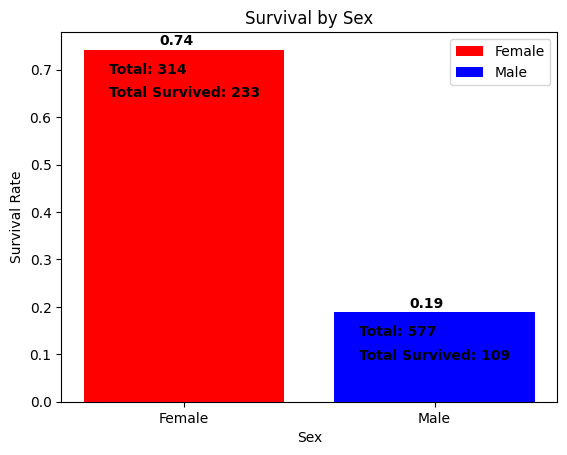

In [45]:
# Survival by sex plot
sex_survival = df.groupby('sex')['survived'].mean().reset_index()
male_total = df[df['sex'] == 'male'].shape[0]
female_total = df[df['sex'] == 'female'].shape[0]

plt.bar(sex_survival['sex'], sex_survival['survived'], label=['Female', 'Male'], color=['red', 'blue'])

for i, v in enumerate(sex_survival['survived']):
    plt.text(i - 0.1, v + 0.01, f"{v:.2f}", color='black', fontweight='bold')
    # show total number of passengers for each sex
    if sex_survival['sex'][i] == 'male':
        plt.text(i - 0.3, v - 0.05, f"Total: {male_total:.0f}", color='black', fontweight='bold')
        plt.text(i - 0.3, v - 0.10, f"Total Survived: {male_total * v:.0f}", color='black', fontweight='bold')
    else:
        plt.text(i - 0.3, v - 0.05, f"Total: {female_total:.0f}", color='black', fontweight='bold')
        plt.text(i - 0.3, v - 0.10, f"Total Survived: {female_total * v:.0f}", color='black', fontweight='bold')

plt.xticks([0, 1], ['Female', 'Male'])
plt.xlabel('Sex')
plt.ylabel('Survival Rate')
plt.title('Survival by Sex')
plt.legend()
plt.show()

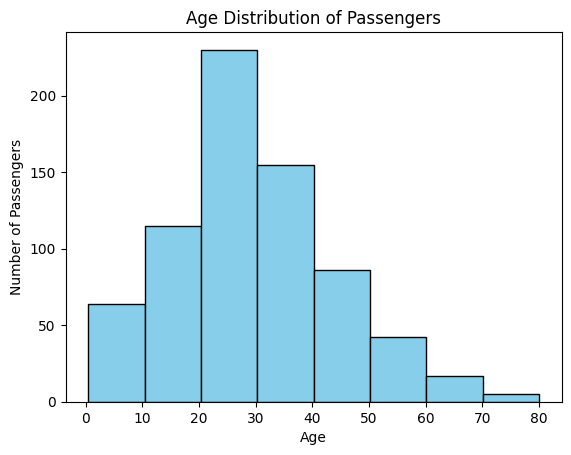

In [16]:
# Age distribution histogram
age_distribution = df['age'].dropna()

plt.hist(age_distribution, bins=8, color='skyblue', edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')
plt.title('Age Distribution of Passengers')
plt.show()

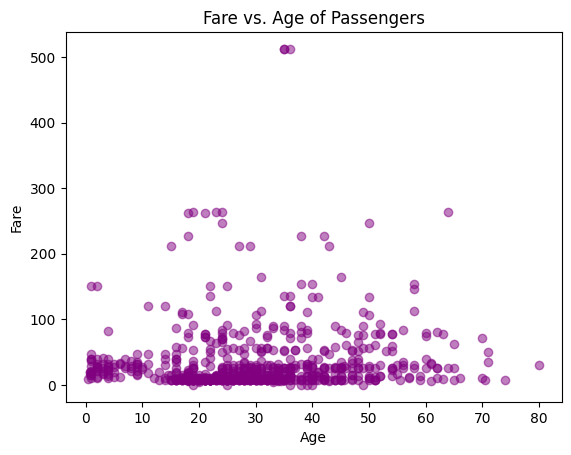

In [13]:
# Fare vs. age scatter plot
plt.scatter(df['age'], df['fare'], alpha=0.5, color='purple')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.title('Fare vs. Age of Passengers')
plt.show()